In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
from matplotlib import pyplot as plt

In [29]:
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score as ari

## load and prep the feature table

In [2]:

feature_ds = xr.open_dataset("../data/features/feature_ds.nc").load()

FEATURES = ["pr_z", "pr3dek_z", "drydays_z", "tas_z", "dtr_z", "smtop_z", "smtop_trend_z", "smmid_z", "smlow_z"]
KEYS = ["region_id", "year", "month", "dekad"]

df = feature_ds[FEATURES].to_dataframe().reset_index()[KEYS + FEATURES]
print("rows in the full grid:", len(df))

rows in the full grid: 71100


In [ ]:
nan_rows = df[df[FEATURES].isnull().any(axis=1)]
print(nan_rows[["year", "month", "dekad"]].drop_duplicates()) # only dekads 1-3 of 2001 should have NaNs
print(df[FEATURES].isnull().sum())                            # NaN count per feature


   year  month  dekad
0  2001      1      1
1  2001      1      2
2  2001      1      3
pr_z               0
pr3dek_z         158
drydays_z          0
tas_z              0
dtr_z              0
smtop_z            0
smtop_trend_z    237
smmid_z            0
smlow_z            0
dtype: int64


In [7]:
# have to drop the NaNs and reproduce row order
df = df.dropna(subset=FEATURES).sort_values(KEYS).reset_index(drop=True)
print("rows after dropping NaNs:", len(df))                   # should be 70,863
assert np.isfinite(df[FEATURES].to_numpy()).all()

rows after dropping NaNs: 70863


In [8]:
# re-standardize the feature matrix
Xs = StandardScaler().fit_transform(df[FEATURES])
print("column means:", Xs.mean(axis=0).round(3))              # about 0
print("column stds: ", Xs.std(axis=0).round(3))               # 1.0


column means: [ 0.  0. -0. -0.  0.  0. -0.  0. -0.]
column stds:  [1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [10]:
# feature summary
summary = df[FEATURES].describe().T[["mean", "std", "min", "max"]].round(2)
print(summary)

               mean  std   min   max
pr_z            0.0  1.0 -3.89  2.45
pr3dek_z        0.0  1.0 -4.30  2.82
drydays_z      -0.0  1.0 -3.39  2.46
tas_z           0.0  1.0 -3.17  2.76
dtr_z           0.0  1.0 -3.26  3.54
smtop_z         0.0  1.0 -3.85  3.65
smtop_trend_z  -0.0  1.0 -3.18  3.92
smmid_z         0.0  1.0 -4.58  4.09
smlow_z         0.0  1.0 -4.52  4.33


## correlation matrix

In [11]:
# Pearson 
corr_p = df[FEATURES].corr()                    
corr_s = df[FEATURES].corr(method="spearman")   # check against skew and outliers
print(corr_p.round(2))

               pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  \
pr_z           1.00      0.55      -0.83  -0.07  -0.45     0.53   
pr3dek_z       0.55      1.00      -0.49  -0.10  -0.39     0.76   
drydays_z     -0.83     -0.49       1.00   0.11   0.47    -0.50   
tas_z         -0.07     -0.10       0.11   1.00   0.36    -0.18   
dtr_z         -0.45     -0.39       0.47   0.36   1.00    -0.47   
smtop_z        0.53      0.76      -0.50  -0.18  -0.47     1.00   
smtop_trend_z  0.49      0.66      -0.46  -0.08  -0.38     0.56   
smmid_z        0.02      0.18      -0.02  -0.15  -0.15     0.40   
smlow_z       -0.00      0.02       0.00  -0.09  -0.06     0.15   

               smtop_trend_z  smmid_z  smlow_z  
pr_z                    0.49     0.02    -0.00  
pr3dek_z                0.66     0.18     0.02  
drydays_z              -0.46    -0.02     0.00  
tas_z                  -0.08    -0.15    -0.09  
dtr_z                  -0.38    -0.15    -0.06  
smtop_z                 0.56     0.

   feature_1      feature_2  pearson  spearman
0       pr_z      drydays_z    -0.83     -0.85
1   pr3dek_z        smtop_z     0.76      0.78
2    smmid_z        smlow_z     0.73      0.71
3   pr3dek_z  smtop_trend_z     0.66      0.65
4    smtop_z  smtop_trend_z     0.56      0.55
5       pr_z       pr3dek_z     0.55      0.57
6       pr_z        smtop_z     0.53      0.56
7  drydays_z        smtop_z    -0.50     -0.50
pairs with |r| > 0.7: 3
largest |Pearson - Spearman| difference: 0.03


   feature_1      feature_2  pearson  spearman
0       pr_z      drydays_z    -0.83     -0.85
1   pr3dek_z        smtop_z     0.76      0.78
2    smmid_z        smlow_z     0.73      0.71
3   pr3dek_z  smtop_trend_z     0.66      0.65
4    smtop_z  smtop_trend_z     0.56      0.55
5       pr_z       pr3dek_z     0.55      0.57
6       pr_z        smtop_z     0.53      0.56
7  drydays_z        smtop_z    -0.50     -0.50
pairs with |r| > 0.7: 3
largest |Pearson - Spearman| difference: 0.03


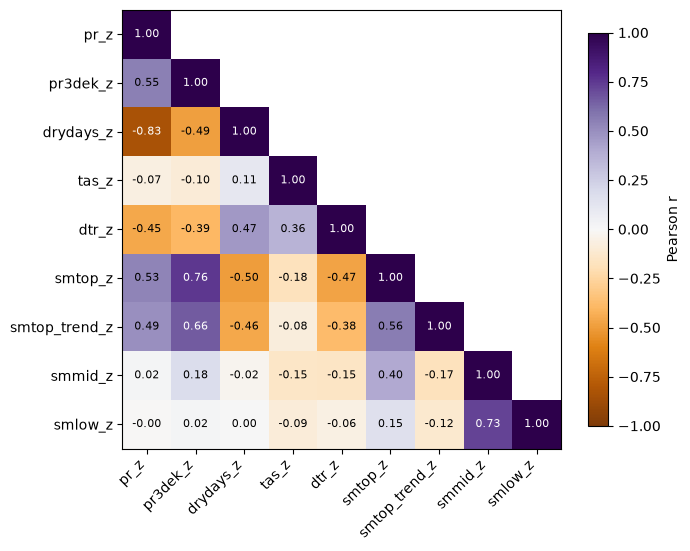

In [19]:
## Overview of corr and plot code by ChatGPT
# all feature pairs, sorted by strength
iu = np.triu_indices(len(FEATURES), k=1)
pairs = pd.DataFrame({"feature_1": [FEATURES[i] for i in iu[0]],
                      "feature_2": [FEATURES[j] for j in iu[1]],
                      "pearson":  corr_p.values[iu],
                      "spearman": corr_s.values[iu]}).round(2)
pairs = pairs.reindex(pairs["pearson"].abs().sort_values(ascending=False).index).reset_index(drop=True)
print(pairs.head(8))
print("pairs with |r| > 0.7:", int((pairs["pearson"].abs() > 0.7).sum()))
print("largest |Pearson - Spearman| difference:", round((pairs["pearson"] - pairs["spearman"]).abs().max(), 2))

# figure for the paper (lower triangle)
mask = np.tril(np.ones_like(corr_p, dtype=bool))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr_p.where(mask), cmap="PuOr", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(i + 1):
        ax.text(j, i, f"{corr_p.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr_p.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
#ax.set_title("Correlation of the standardised features")
plt.tight_layout()
fig.savefig("../output/figures/report/fig_corr_matrix.png", dpi=300)
plt.show()

## PCA diagnostics

In [20]:
# fit PCA on all 9 components
pca = PCA().fit(Xs)
pc_names = [f"PC{i+1}" for i in range(len(FEATURES))]


In [21]:
# explained variance table
evr = pd.DataFrame({"PC": pc_names,
                    "explained": pca.explained_variance_ratio_,
                    "cumulative": pca.explained_variance_ratio_.cumsum()}).round(3)
print(evr)

    PC  explained  cumulative
0  PC1      0.418       0.418
1  PC2      0.209       0.626
2  PC3      0.119       0.745
3  PC4      0.092       0.837
4  PC5      0.055       0.892
5  PC6      0.050       0.942
6  PC7      0.025       0.967
7  PC8      0.018       0.985
8  PC9      0.015       1.000


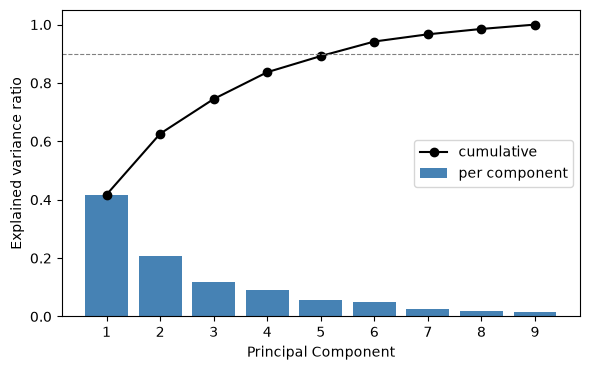

In [23]:
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(range(1, 10), pca.explained_variance_ratio_, color="steelblue", label="per component")
ax.plot(range(1, 10), pca.explained_variance_ratio_.cumsum(), "ko-", label="cumulative")
ax.axhline(0.9, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Principal Component"); ax.set_ylabel("Explained variance ratio")
ax.set_xticks(range(1, 10)); ax.legend(loc="center right")
plt.tight_layout()
fig.savefig("../output/figures/report/fig_pca_scree.png", dpi=300)
plt.show()

     pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  smtop_trend_z  smmid_z  \
PC1  0.42      0.42      -0.41  -0.13  -0.35     0.43           0.37     0.11   
PC2 -0.14     -0.03       0.13  -0.18  -0.05     0.14          -0.25     0.67   
PC3  0.11      0.20      -0.04   0.83   0.43     0.13           0.08     0.14   
PC4 -0.48      0.40       0.55  -0.13   0.13     0.31           0.40     0.01   
PC5  0.19      0.09      -0.20  -0.49   0.81    -0.04           0.09    -0.05   
PC6 -0.05     -0.18       0.04   0.04  -0.12    -0.37           0.63    -0.27   

     smlow_z  
PC1     0.05  
PC2     0.63  
PC3     0.16  
PC4    -0.15  
PC5     0.11  
PC6     0.59  


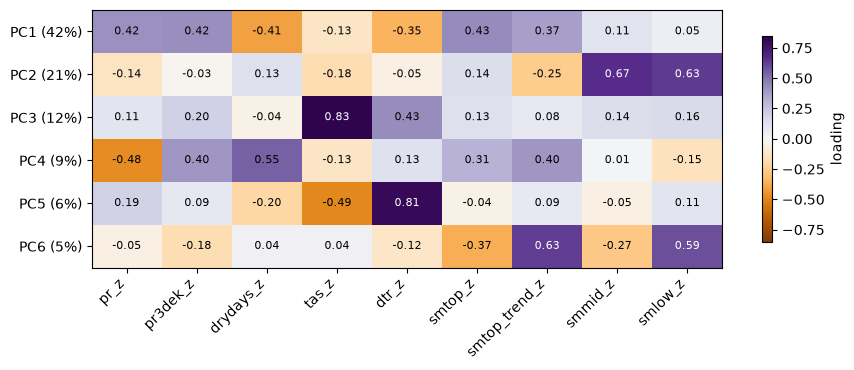

In [26]:
# loadings (rows = PCs, columns = features)
# this nice plot thx to ChatGPT
loadings = pd.DataFrame(pca.components_, columns=FEATURES, index=pc_names)
print(loadings.iloc[:6].round(2))

fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(loadings.iloc[:6], cmap="PuOr", vmin=-0.85, vmax=0.85, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(6), [f"{n} ({v:.0%})" for n, v in zip(pc_names[:6], pca.explained_variance_ratio_[:6])])
for i in range(6):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{loadings.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(loadings.iloc[i, j]) > 0.55 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="loading")
plt.tight_layout()
fig.savefig("../output/figures/report/fig_pca_loadings.png", dpi=300)
plt.show()


In [27]:
# share of each feature's variance kept by the first k PCs
## ChatGPT Code for function 
def retained(k):
    load_k = pca.components_[:k].T * np.sqrt(pca.explained_variance_[:k])
    return pd.Series((load_k ** 2).sum(axis=1), index=FEATURES)

ret = pd.DataFrame({f"{k} PCs": retained(k) for k in (4, 5, 6)}).round(2)
print(ret.sort_values("6 PCs"))
print("min retained with 6 PCs:", ret["6 PCs"].min())

#evr.to_csv(FIG_DIR / "table_pca_variance.csv", index=False)
#loadings.iloc[:6].round(2).to_csv(FIG_DIR / "table_pca_loadings.csv")

               4 PCs  5 PCs  6 PCs
pr3dek_z        0.86   0.86   0.87
smtop_z         0.84   0.84   0.90
pr_z            0.89   0.91   0.91
drydays_z       0.90   0.92   0.92
smmid_z         0.90   0.91   0.94
smtop_trend_z   0.78   0.78   0.96
smlow_z         0.81   0.82   0.97
tas_z           0.88   1.00   1.00
dtr_z           0.67   0.99   1.00
min retained with 6 PCs: 0.87


## choosing k

In [ ]:
## using all 9 features
def evaluate_k(X, k_range=range(2, 11), sample_size=10000, seed=42):
    """
    K-means (inertia, silhouette on a subsample, Davies-Bouldin, seed stability, smallest cluster share)
    and full-covariance GMM (BIC, AIC, seed stability, smallest component share) for each k.
    Seed stability = ARI between two fits that differ only in their random seed.
    """
    rows = []
    for k in k_range:
        km1 = KMeans(k, n_init=10, random_state=seed).fit(X)
        km2 = KMeans(k, n_init=10, random_state=seed + 1).fit(X)
        g1 = GaussianMixture(k, covariance_type="full", n_init=3, max_iter=500, random_state=seed).fit(X)
        g2 = GaussianMixture(k, covariance_type="full", n_init=3, max_iter=500, random_state=seed + 1).fit(X)
        gl1, gl2 = g1.predict(X), g2.predict(X)
        rows.append({
            "k": k,
            "km_inertia": km1.inertia_,
            "km_silhouette": silhouette_score(X, km1.labels_, sample_size=sample_size, random_state=seed),
            "km_davies_bouldin": davies_bouldin_score(X, km1.labels_),
            "km_stability_ari": ari(km1.labels_, km2.labels_),
            "km_min_share": np.bincount(km1.labels_).min() / len(X),
            "gmm_bic": g1.bic(X), "gmm_aic": g1.aic(X),
            "gmm_stability_ari": ari(gl1, gl2),
            "gmm_min_share": np.bincount(gl1, minlength=k).min() / len(X),
        })
        print(f"k={k} done")
    return pd.DataFrame(rows).set_index("k")
res9 = evaluate_k(Xs)


k=2 done
k=3 done
k=4 done
k=5 done
k=6 done
k=7 done
k=8 done
k=9 done
k=10 done
    km_inertia  km_silhouette  km_davies_bouldin  km_stability_ari  \
k                                                                    
2   460101.905          0.237              1.533             0.997   
3   409052.278          0.182              1.753             0.958   
4   369034.770          0.153              1.682             0.958   
5   345925.863          0.139              1.771             0.976   
6   327290.194          0.132              1.736             0.891   
7   311087.954          0.129              1.720             0.994   
8   297424.279          0.128              1.688             0.957   
9   286645.584          0.128              1.675             0.998   
10  277785.848          0.124              1.676             0.936   

    km_min_share      gmm_bic      gmm_aic  gmm_stability_ari  gmm_min_share  
k                                                                   

NameError: name 'FIG_DIR' is not defined

In [32]:

print(res9.round(3))
#res9.round(3).to_csv(FIG_DIR / "table_k_selection_9features.csv")

    km_inertia  km_silhouette  km_davies_bouldin  km_stability_ari  \
k                                                                    
2   460101.905          0.237              1.533             0.997   
3   409052.278          0.182              1.753             0.958   
4   369034.770          0.153              1.682             0.958   
5   345925.863          0.139              1.771             0.976   
6   327290.194          0.132              1.736             0.891   
7   311087.954          0.129              1.720             0.994   
8   297424.279          0.128              1.688             0.957   
9   286645.584          0.128              1.675             0.998   
10  277785.848          0.124              1.676             0.936   

    km_min_share      gmm_bic      gmm_aic  gmm_stability_ari  gmm_min_share  
k                                                                             
2          0.472  1408542.697  1407543.330              0.994          

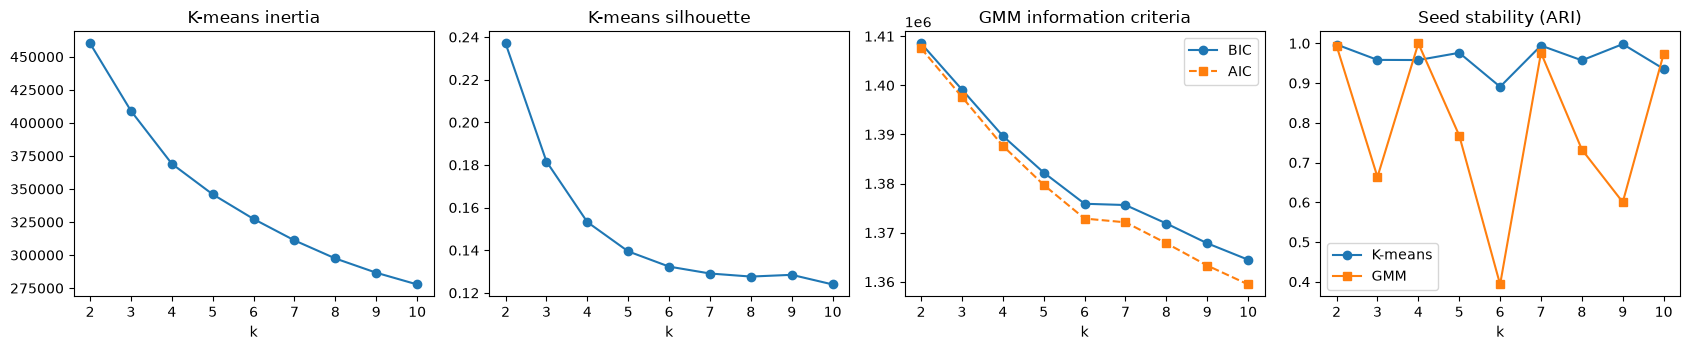

In [34]:
# figure
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
axes[0].plot(res9.index, res9["km_inertia"], "o-");                       axes[0].set_title("K-means inertia")
axes[1].plot(res9.index, res9["km_silhouette"], "o-");                    axes[1].set_title("K-means silhouette")
axes[2].plot(res9.index, res9["gmm_bic"], "o-", label="BIC")
axes[2].plot(res9.index, res9["gmm_aic"], "s--", label="AIC");            axes[2].set_title("GMM information criteria"); axes[2].legend()
axes[3].plot(res9.index, res9["km_stability_ari"], "o-", label="K-means")
axes[3].plot(res9.index, res9["gmm_stability_ari"], "s-", label="GMM");   axes[3].set_title("Seed stability (ARI)"); axes[3].legend()
for ax in axes:
    ax.set_xlabel("k"); ax.set_xticks(range(2, 11))
plt.tight_layout()
fig.savefig("../output/figures/report/fig_k_selection.png", dpi=300)
plt.show()

In [37]:
## now for the 6 PCs
Z6 = PCA(n_components=6).fit_transform(Xs)
res6 = evaluate_k(Z6)
print(res6.round(3))
#res6.round(3).to_csv(FIG_DIR / "table_k_selection_6PCs.csv")

# side-by-side stability, the evidence behind the k = 6 and k = 7 statements
stab = pd.DataFrame({"KM 9 feat": res9["km_stability_ari"], "GMM 9 feat": res9["gmm_stability_ari"],
                     "KM 6 PC": res6["km_stability_ari"], "GMM 6 PC": res6["gmm_stability_ari"]}).round(2)
stab["worst"] = stab.min(axis=1)
print(stab)

k=2 done
k=3 done
k=4 done
k=5 done
k=6 done
k=7 done
k=8 done
k=9 done
k=10 done
    km_inertia  km_silhouette  km_davies_bouldin  km_stability_ari  \
k                                                                    
2   423203.259          0.252              1.463             0.996   
3   372435.709          0.196              1.666             0.966   
4   333596.460          0.165              1.605             0.958   
5   310626.181          0.152              1.670             0.975   
6   291774.833          0.148              1.681             0.723   
7   275985.779          0.143              1.610             0.659   
8   262552.597          0.141              1.587             0.981   
9   251929.703          0.142              1.575             0.955   
10  243177.724          0.141              1.543             0.958   

    km_min_share      gmm_bic      gmm_aic  gmm_stability_ari  gmm_min_share  
k                                                                   

## K-Means, k=5

In [38]:
# fit primary model with k=5
K = 5
WET_COLS = ["pr3dek_z", "smtop_z", "smmid_z"]       # only used to order the labels

# fit
km5 = KMeans(n_clusters=K, n_init=50, random_state=42).fit(Xs)

# order labels from driest (0) to wettest (4) by the mean of WET_COLS
wet = df[WET_COLS].mean(axis=1).to_numpy()
order = pd.Series(wet).groupby(km5.labels_).mean().sort_values().index
mapping = {old: new for new, old in enumerate(order)}
df["km5"] = np.array([mapping[l] for l in km5.labels_])

# profiles, shares, and the wetness composite used for the ordering
prof_km5 = df.groupby("km5")[FEATURES].mean()
share = df["km5"].value_counts(normalize=True).sort_index()
print(share.round(3).tolist())                      # expect 0.16 0.22 0.23 0.25 0.14
print("inertia:", round(km5.inertia_, 1))           # expect about 345,900
print(prof_km5.round(2))
print("ordering composite per regime:", prof_km5[WET_COLS].mean(axis=1).round(2).tolist())

[0.157, 0.223, 0.231, 0.252, 0.137]
inertia: 345925.9
     pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  smtop_trend_z  smmid_z  \
km5                                                                             
0   -1.41     -1.37       1.16   0.43   1.07    -1.09          -1.05    -0.07   
1   -0.14     -0.30       0.30   0.26   0.40    -0.70          -0.18    -0.84   
2   -0.25     -0.06       0.35  -0.22  -0.08     0.03          -0.40     0.71   
3    0.76      0.63      -0.82  -0.08  -0.50     0.57           0.83    -0.48   
4    0.89      1.01      -0.90  -0.38  -0.81     1.31           0.64     1.16   

     smlow_z  
km5           
0       0.10  
1      -0.75  
2       0.68  
3      -0.51  
4       0.89  
ordering composite per regime: [-0.85, -0.62, 0.22, 0.24, 1.16]


all signature checks passed


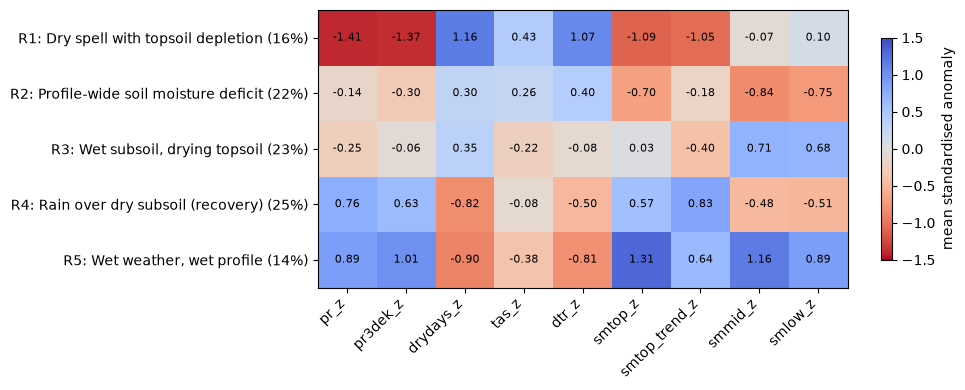

                                   name  share  pr_z  pr3dek_z  drydays_z  \
km5                                                                         
0      Dry spell with topsoil depletion  0.157 -1.41     -1.37       1.16   
1    Profile-wide soil moisture deficit  0.223 -0.14     -0.30       0.30   
2           Wet subsoil, drying topsoil  0.231 -0.25     -0.06       0.35   
3      Rain over dry subsoil (recovery)  0.252  0.76      0.63      -0.82   
4              Wet weather, wet profile  0.137  0.89      1.01      -0.90   

     tas_z  dtr_z  smtop_z  smtop_trend_z  smmid_z  smlow_z  
km5                                                          
0     0.43   1.07    -1.09          -1.05    -0.07     0.10  
1     0.26   0.40    -0.70          -0.18    -0.84    -0.75  
2    -0.22  -0.08     0.03          -0.40     0.71     0.68  
3    -0.08  -0.50     0.57           0.83    -0.48    -0.51  
4    -0.38  -0.81     1.31           0.64     1.16     0.89  


In [ ]:
# ChatGPT suggested naming the signatures, so that different sklearn version would not swap them...
# fix the label ordering
# after fitting apply an explicit name dictionary
# check with an assertion per regime the signature before a name is attached
# names and signature checks: a name is attached only if the profile matches it
KM5_SPEC = {
    0: ("Dry spell with topsoil depletion",
        lambda p: p["pr3dek_z"] < -0.8 and p["smtop_z"] < -0.8 and abs(p["smmid_z"]) < 0.5),
    1: ("Profile-wide soil moisture deficit",
        lambda p: p["smmid_z"] < -0.5 and p["smlow_z"] < -0.5 and p["smtop_z"] < 0),
    2: ("Wet subsoil, drying topsoil",
        lambda p: p["smmid_z"] > 0.4 and p["smlow_z"] > 0.4 and abs(p["pr3dek_z"]) < 0.5),
    3: ("Rain over dry subsoil (recovery)",
        lambda p: p["pr3dek_z"] > 0.3 and p["smtop_z"] > 0.3 and p["smmid_z"] < -0.2 and p["smlow_z"] < -0.2),
    4: ("Wet weather, wet profile",
        lambda p: p["pr3dek_z"] > 0.7 and p["smtop_z"] > 0.8 and p["smmid_z"] > 0.6),
}
for lab, (name, check) in KM5_SPEC.items():
    assert check(prof_km5.loc[lab]), f"Regime {lab} does not match '{name}':\n{prof_km5.loc[lab].round(2)}"
names = {lab: spec[0] for lab, spec in KM5_SPEC.items()}
df["km5_name"] = df["km5"].map(names)
print("all signature checks passed")

# heatmap for the paper
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(prof_km5, cmap="coolwarm_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(K), [f"R{i+1}: {names[i]} ({share[i]:.0%})" for i in range(K)])
for i in range(K):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{prof_km5.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="mean standardised anomaly")
plt.tight_layout()
fig.savefig("../output/figures/report/fig_km5_profiles.png", dpi=300)
plt.show()

# table: regime, name, share, profile
tab_km5 = prof_km5.round(2).copy()
tab_km5.insert(0, "share", share.round(3))
tab_km5.insert(0, "name", [names[i] for i in tab_km5.index])
#tab_km5.to_csv(FIG_DIR / "table_km5_profiles.csv")
print(tab_km5)

## GMM, k=5

In [50]:
# fit (seed 7 was the best-likelihood fit of 10 seeds)
K = 5 
gmm5 = GaussianMixture(n_components=K, covariance_type="full", n_init=10,
                       max_iter=1000, random_state=7).fit(Xs)
assert gmm5.converged_, "GMM did not converge"
print("mean log-likelihood per row:", round(gmm5.score(Xs), 4))      # expect -9.7303

# hard labels and posteriors, ordered from driest (0) to wettest (4)
raw = gmm5.predict(Xs)
post = gmm5.predict_proba(Xs)
wet = df[WET_COLS].mean(axis=1).to_numpy()
order = pd.Series(wet).groupby(raw).mean().sort_values().index
gmap = {old: new for new, old in enumerate(order)}        # raw component -> ordered label
inv = {new: old for old, new in gmap.items()}
df["gmm5"] = np.array([gmap[l] for l in raw])
post_ord = np.empty_like(post)
for old, new in gmap.items():
    post_ord[:, new] = post[:, old]
for i in range(K):
    df[f"gmm5_p{i}"] = post_ord[:, i]
df["gmm5_maxprob"] = post_ord.max(axis=1)

# profiles (mean of the hard-assigned rows, comparable with the K-means profiles)
prof_gmm5 = df.groupby("gmm5")[FEATURES].mean()
share_g = df["gmm5"].value_counts(normalize=True).sort_index()
print("hard shares:", share_g.round(3).tolist())                  # expect 0.18 0.10 0.28 0.38 0.05 (approx.)
print(prof_gmm5.round(2))
print("ordering composite:", prof_gmm5[WET_COLS].mean(axis=1).round(2).tolist())

# names and signature checks
GMM5_SPEC = {
    0: ("Dry spell with topsoil depletion",
        lambda p: p["pr_z"] < -1.0 and p["drydays_z"] > 0.8 and abs(p["smmid_z"]) < 0.5),
    1: ("Deep soil deficit at near-normal weather",
        lambda p: p["smmid_z"] < -0.4 and p["smlow_z"] < -0.4 and abs(p["pr3dek_z"]) < 0.5),
    2: ("Near-normal background",
        lambda p: p.abs().max() < 0.6),
    3: ("Wet weather",
        lambda p: p["pr_z"] > 0.5 and p["drydays_z"] < -0.5 and p["smtop_z"] > 0.2 and abs(p["smmid_z"]) < 0.4),
    4: ("Wet weather, wet profile",
        lambda p: p["smmid_z"] > 1.0 and p["smlow_z"] > 0.7 and p["smtop_z"] > 0.8),
}
for lab, (name, check) in GMM5_SPEC.items():
    assert check(prof_gmm5.loc[lab]), f"Regime {lab} does not match '{name}':\n{prof_gmm5.loc[lab].round(2)}"
names_g = {lab: spec[0] for lab, spec in GMM5_SPEC.items()}
df["gmm5_name"] = df["gmm5"].map(names_g)
print("all signature checks passed")

# GMM-specific outputs: mixing weights, posterior certainty, covariance size
weights = np.array([gmm5.weights_[inv[i]] for i in range(K)])
gmm_info = pd.DataFrame({
    "name": [names_g[i] for i in range(K)],
    "hard share": share_g.round(3),
    "mixing weight": weights.round(3),
    "mean max posterior": df.groupby("gmm5")["gmm5_maxprob"].mean().round(2),
    "mean sd": [np.sqrt(np.diag(gmm5.covariances_[inv[i]])).mean().round(2) for i in range(K)],
    "logdet cov": [np.linalg.slogdet(gmm5.covariances_[inv[i]])[1].round(2) for i in range(K)],
})
print(gmm_info)
print("share of rows with max posterior < 0.6:", round((df["gmm5_maxprob"] < 0.6).mean(), 3))   # expect ~0.20



mean log-likelihood per row: -9.7303
hard shares: [0.179, 0.104, 0.282, 0.38, 0.055]
      pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  smtop_trend_z  \
gmm5                                                                    
0    -1.60     -0.90       1.28   0.12   0.71    -0.74          -0.83   
1     0.19      0.20      -0.11  -0.02  -0.02    -0.24           0.28   
2    -0.24     -0.33       0.40   0.11   0.28    -0.30          -0.29   
3     0.79      0.46      -0.79  -0.08  -0.48     0.47           0.51   
4     0.64      1.07      -0.52  -0.33  -0.31     1.23           0.09   

      smmid_z  smlow_z  
gmm5                    
0        0.06     0.08  
1       -0.85    -0.65  
2        0.05     0.04  
3       -0.08    -0.03  
4        1.75     1.04  
ordering composite: [-0.53, -0.3, -0.19, 0.28, 1.35]
all signature checks passed
                                          name  hard share  mixing weight  \
gmm5                                                                  

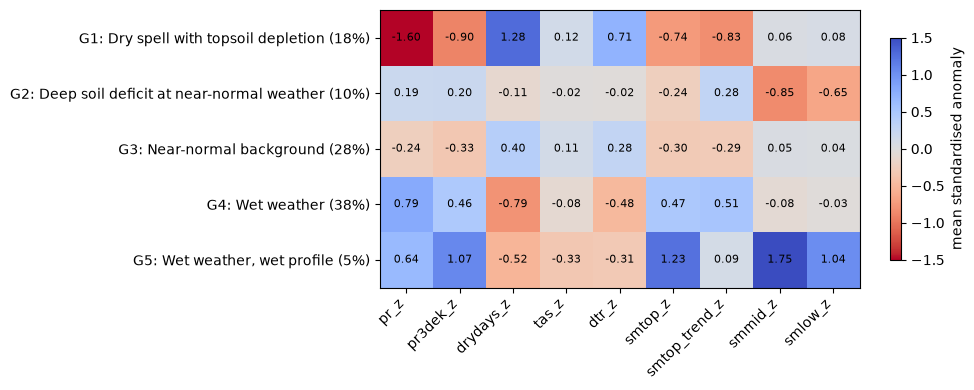

In [51]:
# heatmap for the paper
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(prof_gmm5, cmap="coolwarm_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(K), [f"G{i+1}: {names_g[i]} ({share_g[i]:.0%})" for i in range(K)])
for i in range(K):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{prof_gmm5.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="mean standardised anomaly")
plt.tight_layout()
fig.savefig("../output/figures/report/fig_gmm5_profiles.png", dpi=300)
plt.show()

tab_gmm5 = prof_gmm5.round(2).copy()
tab_gmm5.insert(0, "mean max posterior", gmm_info["mean max posterior"])
tab_gmm5.insert(0, "share", share_g.round(3))
tab_gmm5.insert(0, "name", [names_g[i] for i in tab_gmm5.index])
#tab_gmm5.to_csv(FIG_DIR / "table_gmm5_profiles.csv")
#gmm_info.to_csv(FIG_DIR / "table_gmm5_components.csv")

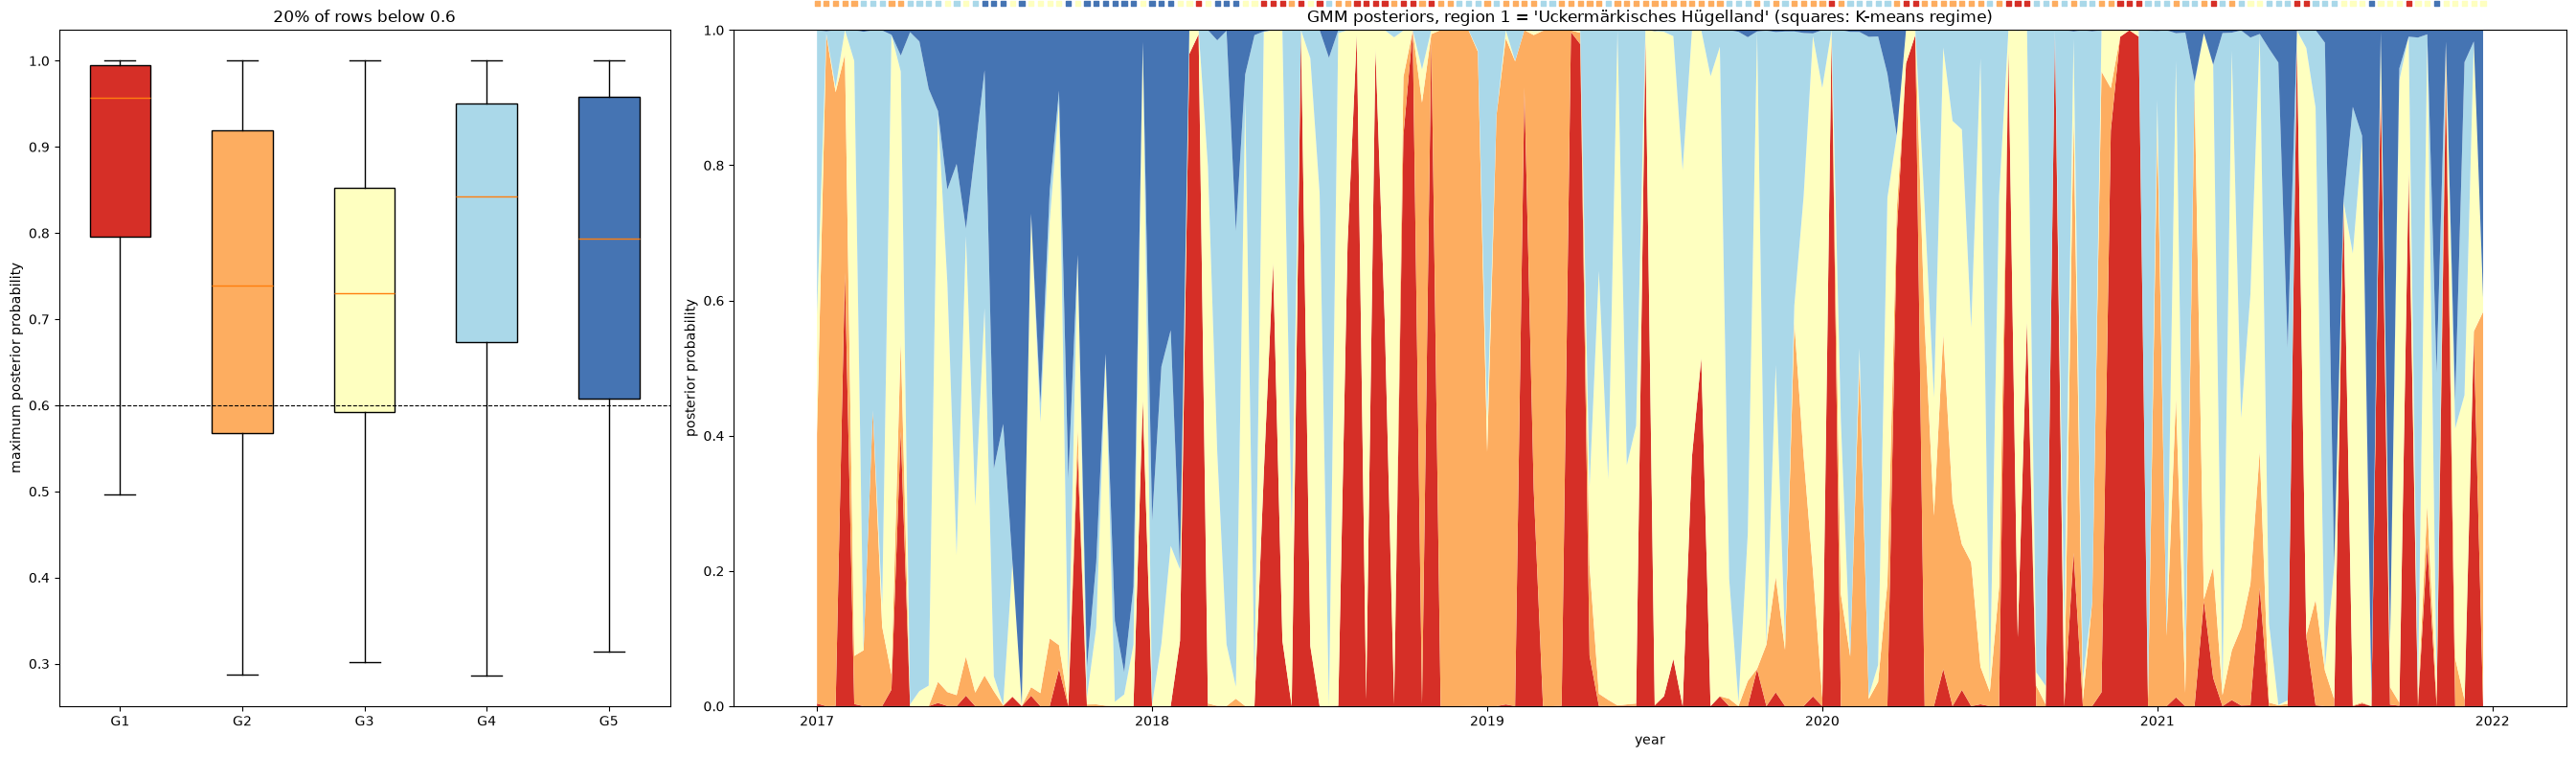

In [99]:
# panel 1: how certain is each hard assignment?
fig, axes = plt.subplots(1, 2, figsize=(27, 8), gridspec_kw={"width_ratios": [1, 3]})
data = [df.loc[df["gmm5"] == i, "gmm5_maxprob"] for i in range(5)]
bp = axes[0].boxplot(data, patch_artist=True, showfliers=False)
for patch, c in zip(bp["boxes"], cols):
    patch.set_facecolor(c)
axes[0].axhline(0.6, color="k", ls="--", lw=0.8)
axes[0].set_xticklabels([f"G{i+1}" for i in range(5)])
axes[0].set_ylabel("maximum posterior probability")
axes[0].set_title(f"{(df['gmm5_maxprob'] < 0.6).mean():.0%} of rows below 0.6")

# panel 2: stacked posteriors through the drought, one region, with the K-means label as a strip
rid = 1                                                       # choose your region
r = df[df["region_id"] == rid].copy()
r["t"] = r["year"] + (r["month"] - 1) / 12 + (r["dekad"] - 1) / 36
r = r[(r["t"] >= 2017) & (r["t"] < 2022)]
axes[1].stackplot(r["t"], [r[c] for c in post_cols], colors=cols)
axes[1].scatter(r["t"], np.full(len(r), 1.04), c=[cols[i] for i in r["km5"]], marker="s", s=14,
                clip_on=False)
axes[1].set_ylim(0, 1); axes[1].set_xlabel("year"); axes[1].set_ylabel("posterior probability")
axes[1].set_title(f"GMM posteriors, region {rid} = 'Uckermärkisches Hügelland' (squares: K-means regime)")
plt.tight_layout()
fig.savefig(FIG_DIR / "fig_gmm_ambiguity.png", dpi=300, bbox_inches="tight")
plt.show()

## Sensitivity tests with k=4

In [52]:
K4 = 4

In [63]:
FIG_DIR = Path("../output/figures/report")
def order_labels(raw_labels, df, wet_cols=WET_COLS):
    """Relabel raw cluster ids so 0 = driest ... k-1 = wettest (mean of wet_cols). Returns labels and the raw->ordered map."""
    wet = df[wet_cols].mean(axis=1).to_numpy()
    order = pd.Series(wet).groupby(raw_labels).mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order)}
    return np.array([mapping[l] for l in raw_labels]), mapping

def plot_profiles(prof, share, names, prefix, fname):
    k = len(prof)
    fig, ax = plt.subplots(figsize=(10, 3.6))
    im = ax.imshow(prof, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
    ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
    ax.set_yticks(range(k), [f"{prefix}{i+1}: {names[i]} ({share[i]:.0%})" for i in range(k)])
    for i in range(k):
        for j in range(len(FEATURES)):
            ax.text(j, i, f"{prof.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.8, label="mean standardised anomaly")
    plt.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=300)
    plt.show()

inertia: 369032.9
shares: [0.22, 0.296, 0.222, 0.262]
     pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  smtop_trend_z  smmid_z  \
km4                                                                             
0   -1.25     -1.15       1.07   0.34   0.94    -1.01          -0.94    -0.11   
1    0.07     -0.09       0.06   0.14   0.14    -0.43          -0.00    -0.70   
2    0.08      0.23       0.04  -0.26  -0.25     0.42          -0.26     1.08   
3    0.91      0.88      -1.01  -0.22  -0.73     0.99           1.01    -0.03   

     smlow_z  
km4           
0       0.05  
1      -0.63  
2       0.99  
3      -0.17  
ordering composite: [-0.76, -0.4, 0.58, 0.61]


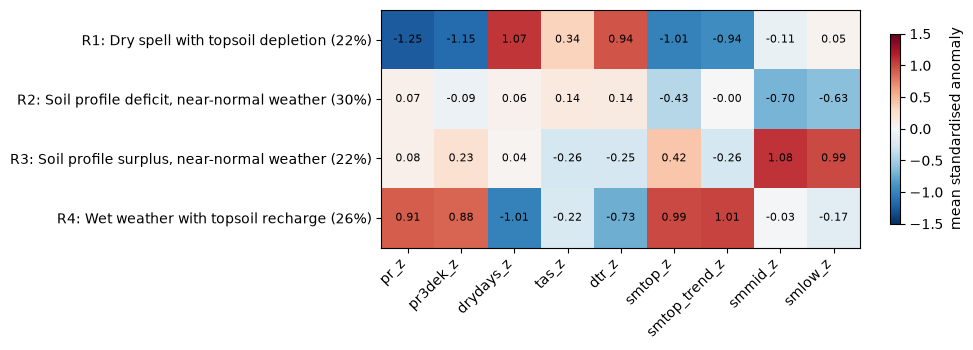

In [65]:
km4 = KMeans(n_clusters=K4, n_init=50, random_state=42).fit(Xs)
df["km4"], _ = order_labels(km4.labels_, df)
prof_km4 = df.groupby("km4")[FEATURES].mean()
share_k4 = df["km4"].value_counts(normalize=True).sort_index()
print("inertia:", round(km4.inertia_, 1))                       # expect about 369,000
print("shares:", share_k4.round(3).tolist())                    # expect 0.22 0.30 0.22 0.26
print(prof_km4.round(2))
print("ordering composite:", prof_km4[WET_COLS].mean(axis=1).round(2).tolist())

KM4_SPEC = {
    0: ("Dry spell with topsoil depletion",
        lambda p: p["pr3dek_z"] < -0.8 and p["smtop_z"] < -0.8 and abs(p["smmid_z"]) < 0.5),
    1: ("Soil profile deficit, near-normal weather",
        lambda p: p["smmid_z"] < -0.5 and p["smlow_z"] < -0.5 and abs(p["pr3dek_z"]) < 0.5),
    2: ("Soil profile surplus, near-normal weather",
        lambda p: p["smmid_z"] > 0.7 and p["smlow_z"] > 0.7 and abs(p["pr3dek_z"]) < 0.5),
    3: ("Wet weather with topsoil recharge",
        lambda p: p["pr3dek_z"] > 0.5 and p["smtop_z"] > 0.5 and abs(p["smmid_z"]) < 0.4),
}
for lab, (name, check) in KM4_SPEC.items():
    assert check(prof_km4.loc[lab]), f"K-means k=4, regime {lab} does not match '{name}':\n{prof_km4.loc[lab].round(2)}"
names_k4 = {lab: s[0] for lab, s in KM4_SPEC.items()}
df["km4_name"] = df["km4"].map(names_k4)
plot_profiles(prof_km4, share_k4, names_k4, "R", "fig_km4_profiles.png")

mean log-likelihood: -9.7881
hard shares: [0.228, 0.271, 0.177, 0.325]
      pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  smtop_trend_z  \
gmm4                                                                    
0    -1.43     -0.83       1.18   0.19   0.74    -0.72          -0.78   
1     0.10      0.04       0.06   0.07   0.15    -0.35           0.15   
2     0.08     -0.17       0.14  -0.10   0.03     0.04          -0.41   
3     0.88      0.64      -0.96  -0.13  -0.66     0.79           0.65   

      smmid_z  smlow_z  
gmm4                    
0        0.03     0.10  
1       -0.54    -0.38  
2        0.70     0.43  
3        0.05     0.01  
ordering composite: [-0.51, -0.28, 0.19, 0.49]
                                           name  hard share  mixing weight  \
gmm4                                                                         
0              Dry spell with topsoil depletion       0.228          0.227   
1     Soil profile deficit, near-normal weather       0.271

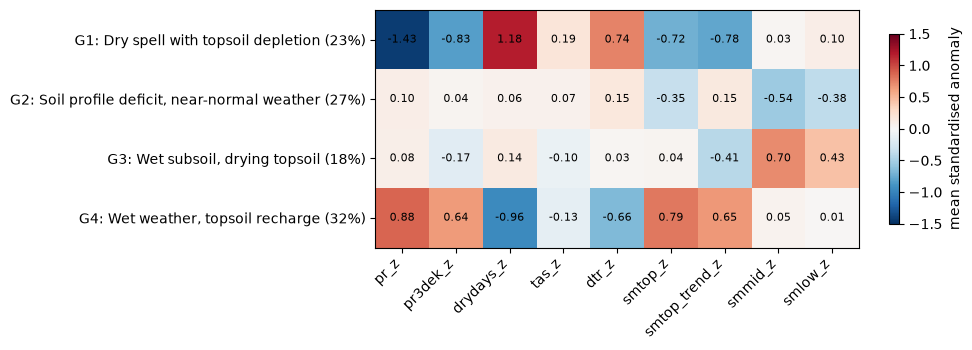

In [69]:
# GMM, k = 4
gmm4 = GaussianMixture(n_components=K4, covariance_type="full", n_init=10,
                       max_iter=1000, random_state=7).fit(Xs)
assert gmm4.converged_, "GMM k=4 did not converge"
raw4 = gmm4.predict(Xs)
df["gmm4"], gmap4 = order_labels(raw4, df)
post4 = gmm4.predict_proba(Xs)
post4_ord = np.empty_like(post4)
for old, new in gmap4.items():
    post4_ord[:, new] = post4[:, old]
df["gmm4_maxprob"] = post4_ord.max(axis=1)

prof_gmm4 = df.groupby("gmm4")[FEATURES].mean()
share_g4 = df["gmm4"].value_counts(normalize=True).sort_index()
print("mean log-likelihood:", round(gmm4.score(Xs), 4))
print("hard shares:", share_g4.round(3).tolist())               # expect about 0.23 0.27 0.18 0.33
print(prof_gmm4.round(2))
print("ordering composite:", prof_gmm4[WET_COLS].mean(axis=1).round(2).tolist())

GMM4_SPEC = {
    0: ("Dry spell with topsoil depletion",
        lambda p: p["pr_z"] < -1.0 and p["drydays_z"] > 0.8 and abs(p["smmid_z"]) < 0.5),
    1: ("Soil profile deficit, near-normal weather",
        lambda p: p["smmid_z"] < -0.3 and p["smlow_z"] < -0.2 and abs(p["pr3dek_z"]) < 0.5),
    2: ("Wet subsoil, drying topsoil",
        lambda p: p["smmid_z"] > 0.4 and p["smlow_z"] > 0.2 and abs(p["pr3dek_z"]) < 0.5),
    3: ("Wet weather, topsoil recharge",
        lambda p: p["pr_z"] > 0.5 and p["drydays_z"] < -0.5 and p["smtop_z"] > 0.5 and abs(p["smmid_z"]) < 0.4),
}
for lab, (name, check) in GMM4_SPEC.items():
    assert check(prof_gmm4.loc[lab]), f"GMM k=4, regime {lab} does not match '{name}':\n{prof_gmm4.loc[lab].round(2)}"
names_g4 = {lab: s[0] for lab, s in GMM4_SPEC.items()}
df["gmm4_name"] = df["gmm4"].map(names_g4)

inv4 = {new: old for old, new in gmap4.items()}
info_g4 = pd.DataFrame({
    "name": [names_g4[i] for i in range(K4)],
    "hard share": share_g4.round(3),
    "mixing weight": [round(gmm4.weights_[inv4[i]], 3) for i in range(K4)],
    "mean max posterior": df.groupby("gmm4")["gmm4_maxprob"].mean().round(2),
    "mean sd": [np.sqrt(np.diag(gmm4.covariances_[inv4[i]])).mean().round(2) for i in range(K4)],
    "logdet cov": [np.linalg.slogdet(gmm4.covariances_[inv4[i]])[1].round(2) for i in range(K4)],
})
print(info_g4)
print("share of rows with max posterior < 0.6:", round((df["gmm4_maxprob"] < 0.6).mean(), 3))   # expect about 0.21
plot_profiles(prof_gmm4, share_g4, names_g4, "G", "fig_gmm4_profiles.png")

In [72]:
(df["gmm4_maxprob"] < 0.6).mean()

np.float64(0.21010964819440328)

In [70]:
# how does k = 4 relate to k = 5? (K-means)
print(pd.crosstab(df["km5"], df["km4"], normalize="index").round(2))     # rows: k=5 regime, columns: k=4 regime
print("ARI K-means k=4 vs k=5:", round(ari(df["km4"], df["km5"]), 3))

km4     0     1     2     3
km5                        
0    1.00  0.00  0.00  0.00
1    0.16  0.84  0.00  0.00
2    0.12  0.19  0.69  0.00
3    0.00  0.26  0.02  0.72
4    0.00  0.00  0.42  0.58
ARI K-means k=4 vs k=5: 0.464


In [71]:
pd.crosstab(df["km5"], df["km4"], normalize="columns").round(2)

km4,0,1,2,3
km5,,,,
0,0.71,0.00,0.00,0.00
1,0.16,0.64,0.00,0.00
2,0.13,0.15,0.72,0.00
3,0.00,0.22,0.02,0.69
4,0.00,0.00,0.26,0.31


In [73]:
## GMM at k = 4
# row-normalised by k = 5 regime: where do the k = 5 GMM regimes come from?
print(pd.crosstab(df["gmm5"], df["gmm4"], normalize="index").round(2))
# column-normalised: where does each k = 4 regime go at k = 5?
print(pd.crosstab(df["gmm5"], df["gmm4"], normalize="columns").round(2))
print("ARI GMM k=4 vs k=5:", round(ari(df["gmm4"], df["gmm5"]), 3))

# K-means, column-normalised, for the same side-by-side view
print(pd.crosstab(df["km5"], df["km4"], normalize="columns").round(2))

gmm4     0     1     2     3
gmm5                        
0     0.98  0.01  0.01  0.00
1     0.04  0.74  0.06  0.17
2     0.16  0.38  0.44  0.02
3     0.00  0.23  0.04  0.73
4     0.03  0.02  0.51  0.44
gmm4     0     1     2     3
gmm5                        
0     0.77  0.01  0.01  0.00
1     0.02  0.28  0.03  0.05
2     0.20  0.39  0.71  0.01
3     0.00  0.32  0.09  0.86
4     0.01  0.00  0.16  0.07
ARI GMM k=4 vs k=5: 0.421
km4     0     1     2     3
km5                        
0    0.71  0.00  0.00  0.00
1    0.16  0.64  0.00  0.00
2    0.13  0.15  0.72  0.00
3    0.00  0.22  0.02  0.69
4    0.00  0.00  0.26  0.31


In [74]:
print(df.groupby("gmm5")[["smmid_z", "smlow_z"]].std().round(2))

      smmid_z  smlow_z
gmm5                  
0        1.07     1.10
1        0.83     0.53
2        0.91     1.01
3        0.76     0.86
4        0.64     1.23


In [75]:
print(df.groupby("km5")[["smmid_z", "smlow_z"]].std().round(2))

     smmid_z  smlow_z
km5                  
0       0.79     0.87
1       0.64     0.73
2       0.70     0.80
3       0.64     0.65
4       0.74     0.86


In [76]:
def variance_explained(df, label_col, cols):
    tot = df[cols].var(ddof=0)
    within = df.groupby(label_col)[cols].var(ddof=0).mul(df[label_col].value_counts(normalize=True).sort_index(), axis=0).sum()
    return (1 - within / tot).round(2)

for col in ["km5", "gmm5", "km4", "gmm4"]:
    print(col, variance_explained(df, col, FEATURES).to_dict())

km5 {'pr_z': 0.59, 'pr3dek_z': 0.56, 'drydays_z': 0.54, 'tas_z': 0.08, 'dtr_z': 0.37, 'smtop_z': 0.61, 'smtop_trend_z': 0.45, 'smmid_z': 0.52, 'smlow_z': 0.41}
gmm5 {'pr_z': 0.75, 'pr3dek_z': 0.32, 'drydays_z': 0.6, 'tas_z': 0.01, 'dtr_z': 0.21, 'smtop_z': 0.3, 'smtop_trend_z': 0.26, 'smmid_z': 0.25, 'smlow_z': 0.1}
km4 {'pr_z': 0.56, 'pr3dek_z': 0.51, 'drydays_z': 0.52, 'tas_z': 0.06, 'dtr_z': 0.35, 'smtop_z': 0.57, 'smtop_trend_z': 0.47, 'smmid_z': 0.4, 'smlow_z': 0.34}
gmm4 {'pr_z': 0.72, 'pr3dek_z': 0.29, 'drydays_z': 0.62, 'tas_z': 0.02, 'dtr_z': 0.27, 'smtop_z': 0.35, 'smtop_trend_z': 0.31, 'smmid_z': 0.17, 'smlow_z': 0.07}


## K-Means vs GMM

In [78]:
from scipy.optimize import linear_sum_assignment

def matched(a, b):
    ct = pd.crosstab(a, b)
    r, c = linear_sum_assignment(-ct.values)
    mapping = {ct.columns[cj]: ct.index[ri] for ri, cj in zip(r, c)}
    return ct.values[r, c].sum() / ct.values.sum(), mapping

rows = []
for k in (4, 5):
    agree, mp = matched(df[f"km{k}"], df[f"gmm{k}"])
    rows.append({"k": k, "ARI": round(ari(df[f"km{k}"], df[f"gmm{k}"]), 3),
                 "matched agreement": round(agree, 3)})
cmp_tab = pd.DataFrame(rows)
print(cmp_tab)                                    # earlier: k=4 0.346 / 67.3%, k=5 0.219 / 51.4%

for k in (4, 5):
    ct = pd.crosstab(df[f"km{k}"], df[f"gmm{k}"])
    print(f"k={k} counts:\n", ct)
    print(f"k={k} row-normalised (K-means regime -> GMM regime):\n", pd.crosstab(df[f"km{k}"], df[f"gmm{k}"], normalize="index").round(2))

# how ambiguous are the K-means regimes in GMM terms? mean GMM posterior by K-means regime (k = 5)
post_cols = [f"gmm5_p{i}" for i in range(5)]
print(df.groupby("km5")[post_cols].mean().round(2))

   k    ARI  matched agreement
0  4  0.348              0.674
1  5  0.219              0.514
k=4 counts:
 gmm4      0      1     2      3
km4                            
0     12079   1603  1896      2
1      1771  13050  2845   3300
2      2286   1793  7293   4367
3         6   2745   499  15328
k=4 row-normalised (K-means regime -> GMM regime):
 gmm4     0     1     2     3
km4                         
0     0.78  0.10  0.12  0.00
1     0.08  0.62  0.14  0.16
2     0.15  0.11  0.46  0.28
3     0.00  0.15  0.03  0.83
k=5 counts:
 gmm5     0     1     2      3     4
km5                                
0     8041   172  2734     71    77
1     1655  3464  7223   3414    25
2     2992   774  8264   3695   679
3        3  2852  1006  13775   208
4        1    90   739   6003  2906
k=5 row-normalised (K-means regime -> GMM regime):
 gmm5     0     1     2     3     4
km5                               
0     0.72  0.02  0.25  0.01  0.01
1     0.10  0.22  0.46  0.22  0.00
2     0.18  0.05  0

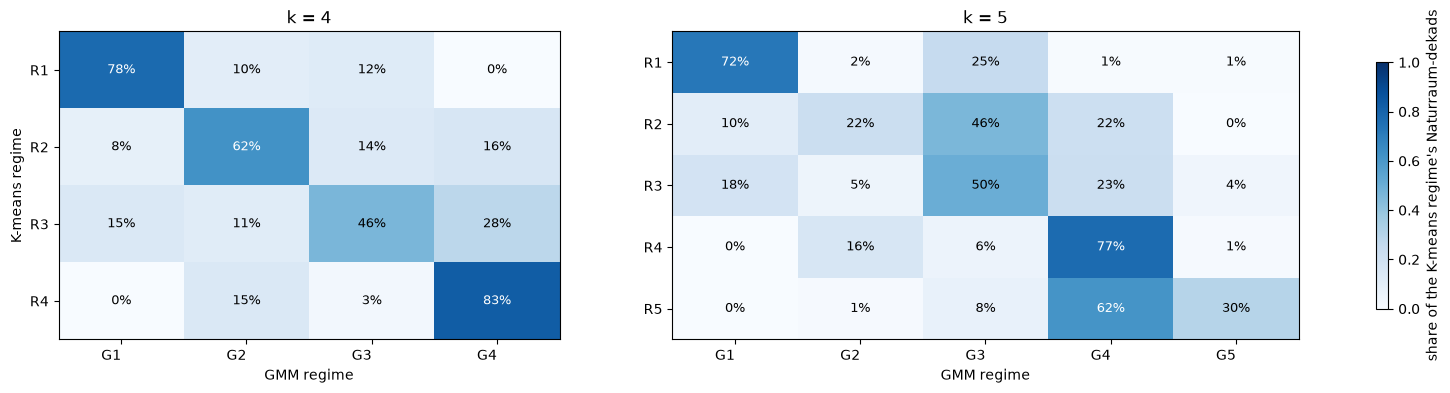

In [87]:
def crosstab_panel(ax, km_col, gmm_col, km_names, gmm_names, title):
    ct = pd.crosstab(df[km_col], df[gmm_col], normalize="index")
    im = ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(ct.shape[1]), [f"G{j+1}" for j in ct.columns], ha="right")
    ax.set_yticks(range(ct.shape[0]), [f"R{i+1}" for i in ct.index])
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            v = ct.values[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if v > 0.55 else "black")
    ax.set_title(title)
    return im

fig, axes = plt.subplots(1, 2, figsize=(20, 4),
                         gridspec_kw={"width_ratios": [4, 5]})
crosstab_panel(axes[0], "km4", "gmm4", names_k4, names_g4, "k = 4")
im = crosstab_panel(axes[1], "km5", "gmm5", names, names_g, "k = 5")
axes[0].set_ylabel("K-means regime")
for ax in axes:
    ax.set_xlabel("GMM regime")
fig.colorbar(im, ax=axes, shrink=0.8, label="share of the K-means regime's Naturraum-dekads")
fig.savefig(FIG_DIR / "fig_km_vs_gmm_crosstab.png", dpi=300, bbox_inches="tight")
plt.show()

## Robustness tests 

In [88]:
# using the 6 PCs
def fit_km(X, k, seed=42):
    return KMeans(k, n_init=50, random_state=seed).fit_predict(X)

def fit_gmm(X, k, seed=7):
    g = GaussianMixture(k, covariance_type="full", n_init=10, max_iter=1000, random_state=seed).fit(X)
    assert g.converged_, f"GMM did not converge (k={k}, seed={seed})"
    return g.predict(X)

# alternative inputs
Z6  = PCA(n_components=6).fit_transform(Xs)                                          # 6 PCs, no whitening
Xs8 = StandardScaler().fit_transform(df[FEATURES].drop(columns="drydays_z"))         # 8 features

variations = {
    "different random seed":        (Xs,  Xs,  43, 8),     # (input KM, input GMM, KM seed, GMM seed)
    "6 PCs instead of 9 features":  (Z6,  Z6,  42, 7),
    "without drydays_z":            (Xs8, Xs8, 42, 7),
}

rows = []
for k in (5, 4):
    for name, (Xkm, Xgm, s_km, s_gm) in variations.items():
        lab_km = fit_km(Xkm, k, s_km)
        lab_gm = fit_gmm(Xgm, k, s_gm)
        rows.append({
            "k": k, "variation": name,
            "K-means ARI": round(ari(df[f"km{k}"], lab_km), 3),
            "K-means matched": round(matched(df[f"km{k}"], lab_km)[0], 3),
            "GMM ARI": round(ari(df[f"gmm{k}"], lab_gm), 3),
            "GMM matched": round(matched(df[f"gmm{k}"], lab_gm)[0], 3),
        })
        print(rows[-1])

robust = pd.DataFrame(rows)
print(robust)

{'k': 5, 'variation': 'different random seed', 'K-means ARI': 0.987, 'K-means matched': np.float64(0.995), 'GMM ARI': 0.793, 'GMM matched': np.float64(0.906)}
{'k': 5, 'variation': '6 PCs instead of 9 features', 'K-means ARI': 0.949, 'K-means matched': np.float64(0.979), 'GMM ARI': 0.239, 'GMM matched': np.float64(0.528)}
{'k': 5, 'variation': 'without drydays_z', 'K-means ARI': 0.735, 'K-means matched': np.float64(0.888), 'GMM ARI': 0.467, 'GMM matched': np.float64(0.671)}
{'k': 4, 'variation': 'different random seed', 'K-means ARI': 0.974, 'K-means matched': np.float64(0.99), 'GMM ARI': 0.964, 'GMM matched': np.float64(0.987)}
{'k': 4, 'variation': '6 PCs instead of 9 features', 'K-means ARI': 0.912, 'K-means matched': np.float64(0.966), 'GMM ARI': 0.346, 'GMM matched': np.float64(0.638)}
{'k': 4, 'variation': 'without drydays_z', 'K-means ARI': 0.754, 'K-means matched': np.float64(0.901), 'GMM ARI': 0.515, 'GMM matched': np.float64(0.745)}
   k                    variation  K-means 

## Plotting clusters over the years

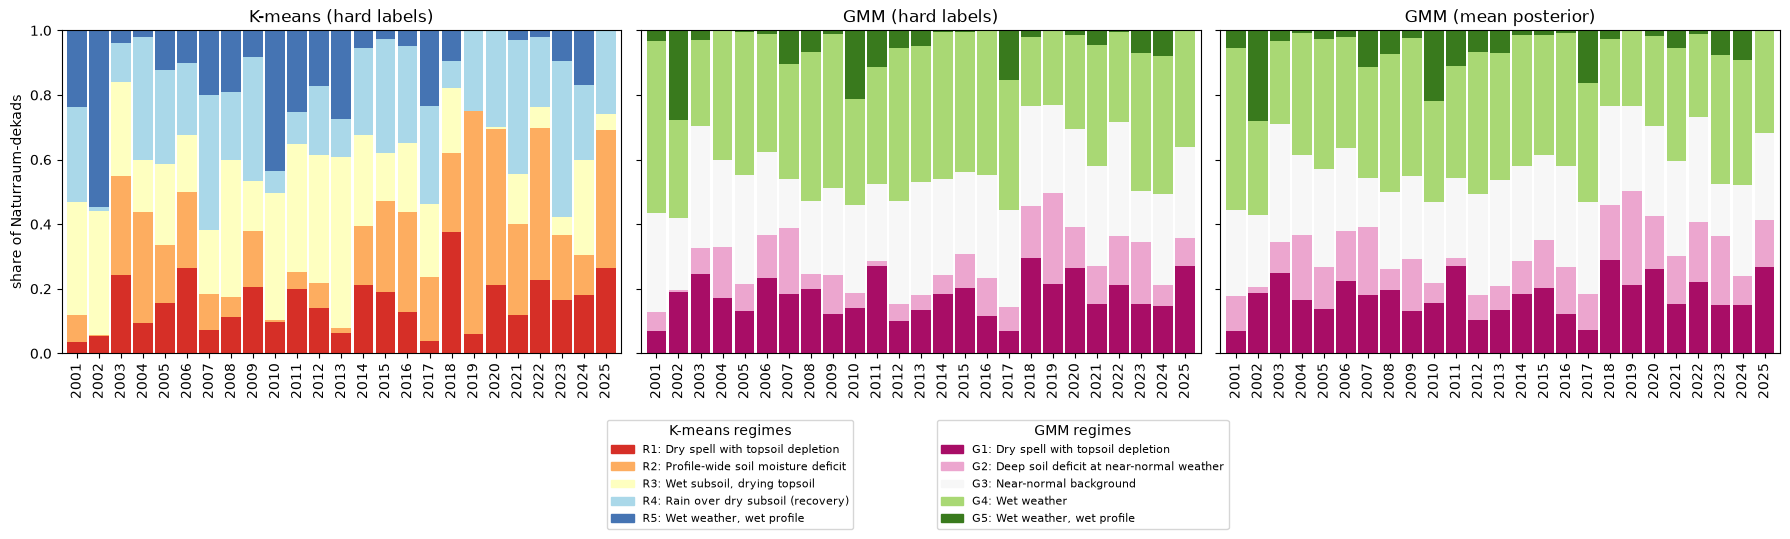

In [100]:
post_cols = [f"gmm5_p{i}" for i in range(5)]

# separate palettes: K-means = red-yellow-blue, GMM = magenta-green, so no colour is used for two regimes
cols_km  = plt.cm.RdYlBu(np.linspace(0.1, 0.9, 5))
cols_gmm = plt.cm.PiYG(np.linspace(0.05, 0.95, 5))
# alternative if PiYG looks too close to RdYlBu on your screen:
# cols_gmm = ["#7b3294", "#c2a5cf", "#bdbdbd", "#a6dba0", "#008837"]

km_year  = pd.crosstab(df["year"], df["km5"], normalize="index")
gmm_year = pd.crosstab(df["year"], df["gmm5"], normalize="index")
gmm_soft = df.groupby("year")[post_cols].mean()
gmm_soft.columns = range(5)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True)
for ax, tab, c, title in zip(axes,
                             [km_year, gmm_year, gmm_soft],
                             [cols_km, cols_gmm, cols_gmm],
                             ["K-means (hard labels)", "GMM (hard labels)", "GMM (mean posterior)"]):
    tab.plot(kind="bar", stacked=True, ax=ax, color=c, width=0.9, legend=False)
    ax.set_title(title)
    ax.set_xlabel("")
axes[0].set_ylabel("share of Naturraum-dekads")

# one legend per method, placed below the panels
h_km  = [plt.Rectangle((0, 0), 1, 1, color=cols_km[i])  for i in range(5)]
h_gmm = [plt.Rectangle((0, 0), 1, 1, color=cols_gmm[i]) for i in range(5)]
l_km  = [f"R{i+1}: {names[i]}"   for i in range(5)]
l_gmm = [f"G{i+1}: {names_g[i]}" for i in range(5)]
fig.legend(h_km,  l_km,  title="K-means regimes", loc="upper right",
           bbox_to_anchor=(0.48, 0.0), fontsize=8)
fig.legend(h_gmm, l_gmm, title="GMM regimes", loc="upper left",
           bbox_to_anchor=(0.52, 0.0), fontsize=8)

plt.tight_layout()
fig.savefig(FIG_DIR / "fig_regime_share_by_year.png", dpi=300, bbox_inches="tight")
plt.show()

In [101]:
pd.set_option("display.width", 200)
P = df[post_cols].to_numpy()

# 1) year plot: the soft GMM table is new, hard tables were seen before
print("GMM mean posterior by year:")
print(df.groupby("year")[post_cols].mean().round(2).set_axis(range(5), axis=1))

# drought-like share (K-means R0+R1, GMM G0+G1), pre-2018 vs 2018 onwards, hard and soft
pre, post_ = df["year"] < 2018, df["year"] >= 2018
for name, series in {
    "K-means R0+R1 (hard)": df["km5"].isin([0, 1]),
    "GMM G0+G1 (hard)":     df["gmm5"].isin([0, 1]),
    "GMM G0+G1 (soft)":     df["gmm5_p0"] + df["gmm5_p1"],
}.items():
    print(f"{name}: 2001-2017 = {series[pre].mean():.2f}, 2018-2025 = {series[post_].mean():.2f}")

# peak year per regime (share of rows), K-means and GMM hard
for col in ("km5", "gmm5"):
    t = pd.crosstab(df["year"], df[col], normalize="index")
    print(col, "peak year per regime:", {int(c): (int(t[c].idxmax()), round(t[c].max(), 2)) for c in t.columns})

# 2) GMM ambiguity: posterior certainty per regime
q = df.groupby("gmm5")["gmm5_maxprob"].quantile([0.1, 0.25, 0.5, 0.75]).unstack().round(2)
q["share < 0.6"] = df.groupby("gmm5")["gmm5_maxprob"].apply(lambda s: (s < 0.6).mean()).round(2)
print("\nmax posterior per regime:\n", q)
print("overall share < 0.6:", round((df["gmm5_maxprob"] < 0.6).mean(), 3),
      "| share < 0.9:", round((df["gmm5_maxprob"] < 0.9).mean(), 3))

# which regimes are confused? second most likely component for ambiguous rows
amb = df["gmm5_maxprob"] < 0.6
second = np.argsort(P, axis=1)[:, -2]
print("\nfirst vs second component, rows with max posterior < 0.6 (row-normalised):")
print(pd.crosstab(df.loc[amb, "gmm5"], pd.Series(second, index=df.index)[amb], normalize="index").round(2))

# when is it ambiguous? by month and by year
print("\nshare < 0.6 by month:", df.groupby("month")["gmm5_maxprob"].apply(lambda s: (s < 0.6).mean()).round(2).to_dict())
print("share < 0.6 by year: ", df.groupby("year")["gmm5_maxprob"].apply(lambda s: (s < 0.6).mean()).round(2).to_dict())

# 3) flicker: how often does the label change from one dekad to the next?
def change_rate(col):
    return np.mean([1 - (g[col].to_numpy()[:-1] == g[col].to_numpy()[1:]).mean()
                    for _, g in df.groupby("region_id")])
print("\nshare of consecutive dekads with a label change: K-means", round(change_rate("km5"), 2),
      "| GMM", round(change_rate("gmm5"), 2))

# 4) the timeline panel: which region and window, and what happens there
rid = 1                                   # <- the region you plotted
w = df[(df["region_id"] == rid) & (df["year"].between(2017, 2021))]
print(f"\nregion {rid}, 2017-2021: K-means changes {int((w['km5'].diff().fillna(0) != 0).sum())}, "
      f"GMM changes {int((w['gmm5'].diff().fillna(0) != 0).sum())}, of {len(w)} dekads; "
      f"share < 0.6: {(w['gmm5_maxprob'] < 0.6).mean():.2f}")

GMM mean posterior by year:
         0     1     2     3     4
year                              
2001  0.07  0.11  0.27  0.50  0.05
2002  0.19  0.02  0.22  0.29  0.28
2003  0.25  0.10  0.36  0.26  0.03
2004  0.17  0.20  0.25  0.38  0.01
2005  0.14  0.13  0.30  0.40  0.03
2006  0.23  0.15  0.26  0.34  0.02
2007  0.18  0.21  0.15  0.34  0.11
2008  0.20  0.07  0.24  0.43  0.07
2009  0.13  0.16  0.26  0.43  0.02
2010  0.16  0.06  0.25  0.31  0.22
2011  0.27  0.02  0.25  0.35  0.11
2012  0.10  0.08  0.31  0.44  0.07
2013  0.13  0.08  0.33  0.39  0.07
2014  0.19  0.10  0.29  0.41  0.01
2015  0.20  0.15  0.26  0.37  0.01
2016  0.12  0.15  0.31  0.41  0.01
2017  0.07  0.11  0.28  0.37  0.16
2018  0.29  0.17  0.31  0.21  0.03
2019  0.21  0.29  0.26  0.23  0.00
2020  0.26  0.16  0.28  0.28  0.02
2021  0.15  0.15  0.29  0.35  0.05
2022  0.22  0.19  0.33  0.26  0.01
2023  0.15  0.21  0.16  0.40  0.08
2024  0.15  0.09  0.28  0.39  0.09
2025  0.27  0.15  0.27  0.32  0.00
K-means R0+R1 (hard): 2001-

## Mapping clusters over space

In [105]:
from matplotlib.colors import ListedColormap

In [103]:
natraum_3035 = gpd.read_file("../data/brandenburg_shape/naturraum_scholz_ohne_Berlin_regionid.gpkg", layer="natraum_scholz_ohneBerlin_regionid")

In [106]:
gdf = natraum_3035[["region_id", "NAME_UNTER", "geometry"]].copy()
gdf["region_id"] = gdf["region_id"].astype(int)
assert set(gdf["region_id"]) == set(df["region_id"]), "region ids differ between polygons and results"

def to_map(series, name):
    """Attach a per-region Series (index = region_id) to the polygons."""
    return gdf.merge(series.rename(name).reset_index(), on="region_id")

cmap_km = ListedColormap(cols_km)
overall = df["km5"].value_counts(normalize=True).sort_index()

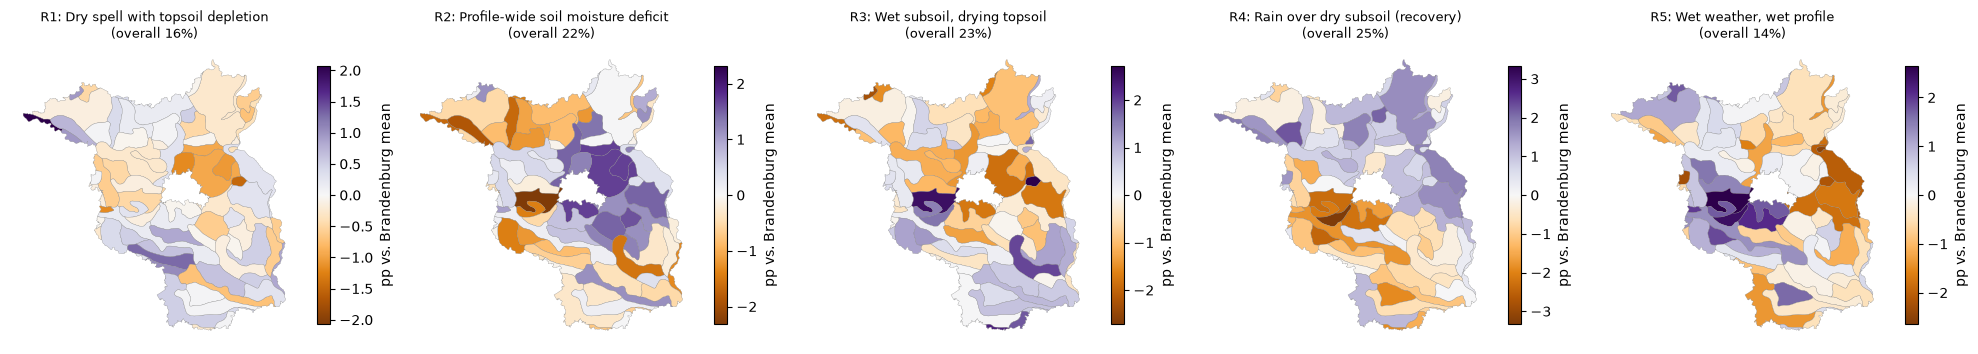

range of regime share across the 79 regions (min, max):
       min    max  overall
km5                       
0    0.142  0.177    0.157
1    0.200  0.240    0.223
2    0.208  0.259    0.231
3    0.219  0.274    0.252
4    0.113  0.164    0.137


In [107]:
share_reg = pd.crosstab(df["region_id"], df["km5"], normalize="index")     # region x regime
diff = (share_reg - overall) * 100

fig, axes = plt.subplots(1, 5, figsize=(20, 4.6))
for i, ax in enumerate(axes):
    m = to_map(diff[i], "d")
    lim = max(abs(m["d"].min()), abs(m["d"].max()))
    m.plot(column="d", cmap="PuOr", vmin=-lim, vmax=lim, ax=ax, edgecolor="grey", linewidth=0.2,
           legend=True, legend_kwds={"shrink": 0.6, "label": "pp vs. Brandenburg mean"})
    ax.set_title(f"R{i+1}: {names[i]}\n(overall {overall[i]:.0%})", fontsize=9)
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(FIG_DIR / "fig_map_regime_share_anomaly.png", dpi=300, bbox_inches="tight")
plt.show()

print("range of regime share across the 79 regions (min, max):")
print(pd.DataFrame({"min": share_reg.min(), "max": share_reg.max(), "overall": overall}).round(3))

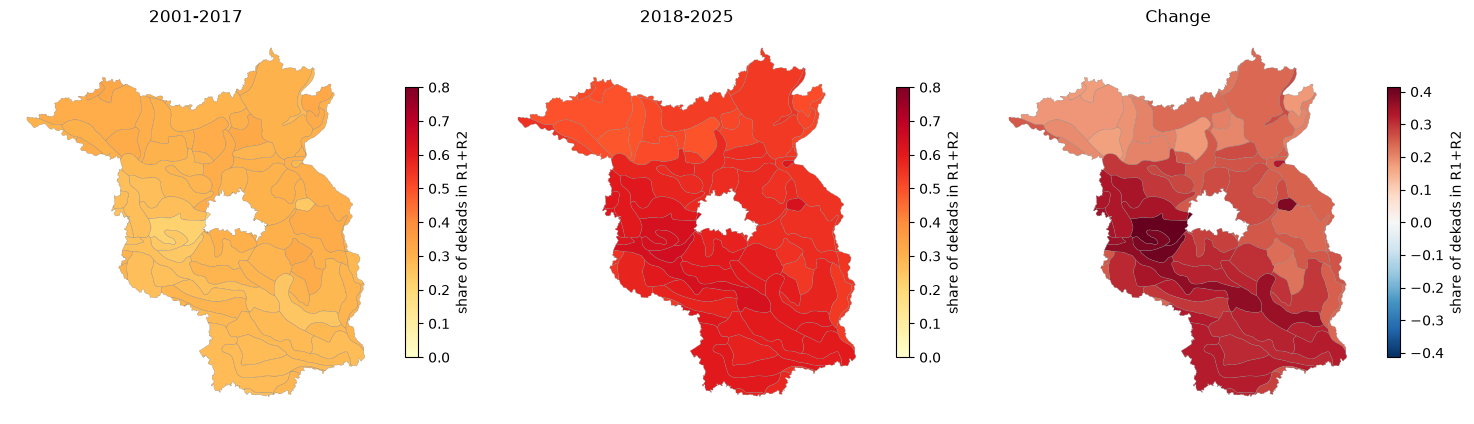

            pre  post  change                         NAME_UNTER
region_id                                                       
42         0.22  0.63    0.41  Brandenburg-Potsdamer Havelgebiet
48         0.24  0.65    0.40                    Beelitzer Heide
46         0.24  0.63    0.39                      Lehniner Land
37         0.24  0.63    0.38      Buckower Hügel und Kesselland
50         0.26  0.63    0.37    Baruther Tal (mit Fiener Bruch)
            pre  post  change                       NAME_UNTER
region_id                                                     
19         0.32  0.49    0.17                  Kyritzer PLatte
4          0.33  0.50    0.17  Parchim-Meyenburger Sandflächen
6          0.33  0.51    0.18                     Ruhner Berge
5          0.33  0.50    0.18        Uckermärkisches Hügelland
16         0.31  0.49    0.18                  Granseer Platte
change: min 0.17 max 0.41


In [108]:
drought = df["km5"].isin([0, 1])
pre  = drought[df["year"] < 2018].groupby(df["region_id"]).mean()
post = drought[df["year"] >= 2018].groupby(df["region_id"]).mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, s, title, cmap, lim in [(axes[0], pre,  "2001-2017", "YlOrRd", (0, 0.8)),
                                (axes[1], post, "2018-2025", "YlOrRd", (0, 0.8)),
                                (axes[2], post - pre, "Change", "RdBu_r", None)]:
    m = to_map(s, "v")
    kw = dict(vmin=lim[0], vmax=lim[1]) if lim else dict(vmin=-m["v"].abs().max(), vmax=m["v"].abs().max())
    m.plot(column="v", cmap=cmap, ax=ax, edgecolor="grey", linewidth=0.2, legend=True,
           legend_kwds={"shrink": 0.6, "label": "share of dekads in R1+R2"}, **kw)
    ax.set_title(title); ax.set_axis_off()
plt.tight_layout()
fig.savefig(FIG_DIR / "fig_map_drought_share_pre_post.png", dpi=300, bbox_inches="tight")
plt.show()

tab = pd.DataFrame({"pre": pre, "post": post, "change": post - pre}).join(gdf.set_index("region_id")["NAME_UNTER"])
print(tab.sort_values("change", ascending=False).head(5).round(2))
print(tab.sort_values("change").head(5).round(2))
print("change: min", round(tab["change"].min(), 2), "max", round(tab["change"].max(), 2))

In [110]:
cent = gdf.set_index("region_id").geometry.centroid
tab["northing"] = cent.y.reindex(tab.index)
tab["easting"] = cent.x.reindex(tab.index)
print(tab[["change", "pre", "post", "northing", "easting"]].corr().round(2)[["northing", "easting"]])

# 2018 and 2019 separately, drought-like share over the whole year, no map needed
for yr in (2018, 2019):
    s = df[df["year"] == yr]["km5"].isin([0, 1]).groupby(df["region_id"]).mean()
    print(yr, "min", round(s.min(), 2), "max", round(s.max(), 2), "| top 3:",
          gdf.set_index("region_id").loc[s.nlargest(3).index, "NAME_UNTER"].tolist())

          northing  easting
change       -0.58     0.03
pre           0.47     0.06
post         -0.60     0.08
northing      1.00    -0.33
easting      -0.33     1.00
2018 min 0.47 max 0.75 | top 3: ['Niederlausitzer Randhügel', 'Großenhainer Pflege', 'Westliche Fläminghochfläche']
2019 min 0.67 max 0.83 | top 3: ['Mittelelbe Niederung', 'Lausitzer Grenzwall', 'Kirchhain-Finsterwalder Becken']


C:\Users\frank\AppData\Local\Temp\ipykernel_19424\2439183748.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  cent = gdf.set_index("region_id").geometry.centroid


2018 dominant regime counts: {0: 67, 1: 7, 2: 5} | drought-like share: min 0.44 max 0.94
2019 dominant regime counts: {1: 79} | drought-like share: min 0.72 max 1.0


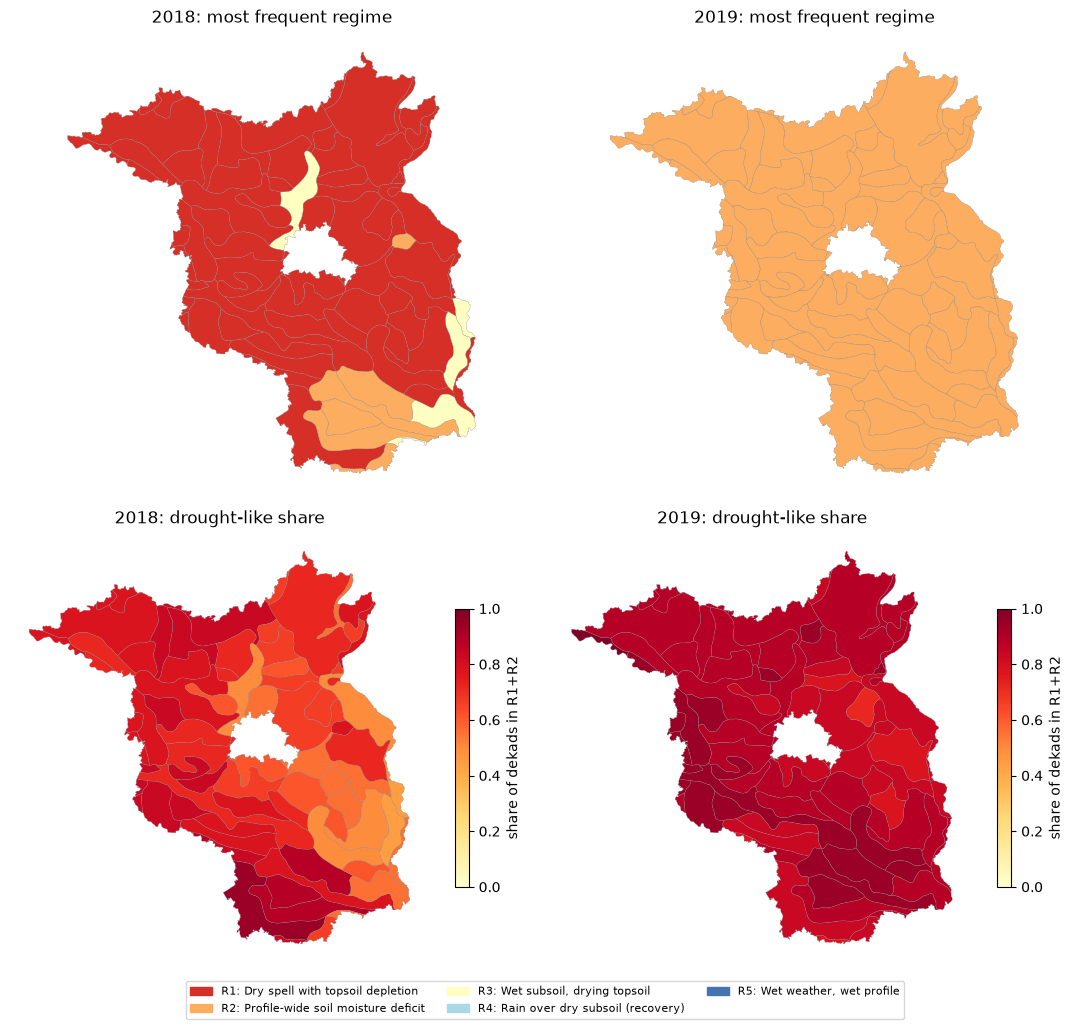

In [109]:
gs = df[df["month"].between(4, 9)]
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for j, yr in enumerate((2018, 2019)):
    g = gs[gs["year"] == yr]
    dom = g.groupby("region_id")["km5"].agg(lambda s: s.value_counts().idxmax())
    m = to_map(dom, "dom")
    m.plot(column="dom", cmap=cmap_km, vmin=-0.5, vmax=4.5, ax=axes[0, j], edgecolor="grey", linewidth=0.2)
    axes[0, j].set_title(f"{yr}: most frequent regime"); axes[0, j].set_axis_off()

    dshare = g["km5"].isin([0, 1]).groupby(g["region_id"]).mean()
    to_map(dshare, "v").plot(column="v", cmap="YlOrRd", vmin=0, vmax=1, ax=axes[1, j],
                             edgecolor="grey", linewidth=0.2, legend=True,
                             legend_kwds={"shrink": 0.6, "label": "share of dekads in R1+R2"})
    axes[1, j].set_title(f"{yr}: drought-like share"); axes[1, j].set_axis_off()
    print(yr, "dominant regime counts:", dom.value_counts().sort_index().to_dict(),
          "| drought-like share: min", round(dshare.min(), 2), "max", round(dshare.max(), 2))

h = [plt.Rectangle((0, 0), 1, 1, color=cols_km[i]) for i in range(5)]
fig.legend(h, [f"R{i+1}: {names[i]}" for i in range(5)], loc="lower center", ncol=3, fontsize=8,
           bbox_to_anchor=(0.5, -0.03))
plt.tight_layout()
fig.savefig(FIG_DIR / "fig_map_2018_2019.png", dpi=300, bbox_inches="tight")
plt.show()